[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zjelveh/zjelveh.github.io/blob/master/files/ccjs418e_fall2026/9_merging.ipynb)

**Save your own copy.**
1. Click File > Save a copy in Drive.
2. Rename it.
3. Work in your copy.

---

# 9. Merging: Arrest Rates by Borough
## CCJS 418E: Coding for Criminology — Fall 2026

In the visualization notebook, Brooklyn and Manhattan recorded the most arrests. The boroughs also differ in how many people live in them: Brooklyn has about 2.6 million residents and Staten Island about 470,000. A **rate** puts places of different sizes on the same scale. Today we will calculate arrests per 100,000 residents.

The arrest counts come from the NYPD, and the population figures come from the Census Bureau. Each source stores its numbers in its own table. **Merging** lines up the rows of two tables that describe the same place and year, so their numbers sit side by side.

> Which borough had the highest arrest rate in 2015, and is it the borough with the most arrests?

One cell begins with `# Expected KeyError`. It fails on purpose. Read the error, then run the next cell.

In [1]:
# Show the result of every line in a cell, so one cell can display several outputs
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'

# pandas works with tables of data
import pandas as pd
# NumPy handles the numbers stored inside pandas tables
import numpy as np
# Seaborn draws the charts
import seaborn as sns
# Matplotlib adds titles and labels to Seaborn charts
import matplotlib.pyplot as plt

# Print NumPy numbers as plain values, such as 3 instead of np.int64(3)
np.set_printoptions(legacy="1.25")
# Draw charts on a white background with light grid lines
sns.set_style('whitegrid')
# Make every chart 9 inches wide and 4 inches tall
plt.rcParams['figure.figsize'] = (9, 4)

## Setup: Three Tables

**`arrests`: one row represents one borough in one year.** These are NYPD arrests from the same 2013–2015 extract as the datetime and visualization notebooks.

| Column | Meaning |
|---|---|
| `borough` | Borough where the arrest was made |
| `year` | 2013, 2014, or 2015 |
| `arrests` | Recorded felony and misdemeanor arrests |
| `felony_arrests`, `misdemeanor_arrests` | The two parts of `arrests` |

**`population`: one row represents one county in one year.** These are Census Bureau estimates of the number of residents on July 1 of each year from 2010 to 2019.

| Column | Meaning |
|---|---|
| `county` | County name used by the Census Bureau |
| `year` | 2010 through 2019 |
| `population` | Estimated residents on July 1 |

**`places`: one row represents one borough.** It lists each borough's county name.

In [2]:
arrests_url = 'https://raw.githubusercontent.com/zjelveh/zjelveh.github.io/refs/heads/master/files/ccjs418e_fall2026/nyc_arrests_borough_year.csv'
population_url = 'https://raw.githubusercontent.com/zjelveh/zjelveh.github.io/refs/heads/master/files/ccjs418e_fall2026/nyc_county_population.csv'
places_url = 'https://raw.githubusercontent.com/zjelveh/zjelveh.github.io/refs/heads/master/files/ccjs418e_fall2026/nyc_borough_county.csv'

arrests = pd.read_csv(filepath_or_buffer=arrests_url)
population = pd.read_csv(filepath_or_buffer=population_url)
places = pd.read_csv(filepath_or_buffer=places_url)

arrests.shape
population.shape
places.shape

(15, 5)

(50, 3)

(5, 2)

## Part 1: Look at the Tables

`arrests` has 15 rows: five boroughs, each with three years. Display all of it.

In [3]:
arrests

,borough,year,arrests,felony_arrests,misdemeanor_arrests
0,Bronx,2013,83709,20346,63363
1,Bronx,2014,82690,20787,61903
2,Bronx,2015,72406,19526,52880
3,Brooklyn,2013,98020,29516,68504
4,Brooklyn,2014,95174,28973,66201
5,Brooklyn,2015,83892,27775,56117
6,Manhattan,2013,97233,21593,75640
7,Manhattan,2014,93787,21165,72622
8,Manhattan,2015,83602,21050,62552
9,Queens,2013,69173,20540,48633


`population` has 50 rows: five counties, each with ten years. Display its first rows and the years it covers.

In [4]:
population.head(n=6)
population['year'].unique()

,county,year,population
0,Bronx County,2010,1387298
1,Bronx County,2011,1397335
2,Bronx County,2012,1411496
3,Bronx County,2013,1421928
4,Bronx County,2014,1430942
5,Bronx County,2015,1440005


array([2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019])

### Which Columns Could Link the Tables?

Both tables have a `year` column. Each also names a place: `arrests` uses `borough`, and `population` uses `county`. Compare the place names.

In [5]:
arrests['borough'].unique()
population['county'].unique()

array(['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island'],
      dtype=object)

array(['Bronx County', 'Kings County', 'New York County', 'Queens County',
       'Richmond County'], dtype=object)

New York City's five boroughs are also counties, and the Census Bureau uses the county names. Three have different names: Brooklyn is Kings County, Manhattan is New York County, and Staten Island is Richmond County. The other two add the word "County." The `places` table records each borough's county name.

In [6]:
places

,borough,county
0,Bronx,Bronx County
1,Brooklyn,Kings County
2,Manhattan,New York County
3,Queens,Queens County
4,Staten Island,Richmond County


## Part 2: Add County Names to the Arrest Table

`pd.merge()` combines two tables by matching values in a column that both tables share. `on=` names that column.

A first attempt merges `arrests` with `population` on `borough`. Run the next cell and read its error.

In [ ]:
# Expected KeyError: merge on a column that only one table has
pd.merge(left=arrests, right=population, on='borough')

The error names `'borough'`: `population` has no column with that name. A merge matches rows using a column with the same name in both tables, and the values in that column have to match too.

`arrests` and `places` share the `borough` column. Merging them adds each borough's county name to the arrest rows.

| Argument | Meaning |
|---|---|
| `left=arrests` | The table whose rows we keep |
| `right=places` | The table that supplies the new column |
| `on='borough'` | The column both tables share |
| `how='left'` | Keep every row of the left table |

In [8]:
arrests_county = pd.merge(left=arrests, right=places, on='borough', how='left')

arrests_county.head(n=6)
arrests_county.shape

,borough,year,arrests,felony_arrests,misdemeanor_arrests,county
0,Bronx,2013,83709,20346,63363,Bronx County
1,Bronx,2014,82690,20787,61903,Bronx County
2,Bronx,2015,72406,19526,52880,Bronx County
3,Brooklyn,2013,98020,29516,68504,Kings County
4,Brooklyn,2014,95174,28973,66201,Kings County
5,Brooklyn,2015,83892,27775,56117,Kings County


(15, 6)

`places` lists each borough once, and `arrests` lists each borough three times, once per year. The merge copies the county name onto all three rows, so `arrests_county` still has 15 rows, now with a `county` column.

## Part 3: Match on County and Year

`arrests_county` and `population` now share two columns: `county` and `year`. First, merge on `county` alone and count the rows.

In [9]:
county_only = pd.merge(left=arrests_county, right=population, on='county', how='left')

county_only.shape
county_only.head(n=3)

(150, 8)

,borough,year_x,arrests,felony_arrests,misdemeanor_arrests,county,year_y,population
0,Bronx,2013,83709,20346,63363,Bronx County,2010,1387298
1,Bronx,2013,83709,20346,63363,Bronx County,2011,1397335
2,Bronx,2013,83709,20346,63363,Bronx County,2012,1411496


The result has 150 rows. Each arrest row matched all ten years of its county's population: the Bronx's 2013 arrests sit beside the Bronx population for 2010, 2011, and every other year. Both tables had a `year` column, so pandas kept both and named them `year_x` (from the left table) and `year_y` (from the right table).

Each arrest row belongs with one population row: the same county **and** the same year. A list in `on=` matches on every column in the list.

In [10]:
rates = pd.merge(left=arrests_county, right=population, on=['county', 'year'], how='left')

rates.shape
rates.head(n=6)

(15, 7)

,borough,year,arrests,felony_arrests,misdemeanor_arrests,county,population
0,Bronx,2013,83709,20346,63363,Bronx County,1421928
1,Bronx,2014,82690,20787,61903,Bronx County,1430942
2,Bronx,2015,72406,19526,52880,Bronx County,1440005
3,Brooklyn,2013,98020,29516,68504,Kings County,2587684
4,Brooklyn,2014,95174,28973,66201,Kings County,2601513
5,Brooklyn,2015,83892,27775,56117,Kings County,2608794


## Part 4: Which Rows Does a Merge Keep?

`how=` decides which rows appear in the result.

| `how=` | Keeps |
|---|---|
| `'left'` | Every row of the left table |
| `'inner'` | Rows that match in both tables |
| `'right'` | Every row of the right table |

`population` covers 2010–2019, and `arrests_county` covers 2013–2015. Compare the results.

In [11]:
pd.merge(left=arrests_county, right=population, on=['county', 'year'], how='inner').shape

right_merge = pd.merge(left=arrests_county, right=population, on=['county', 'year'], how='right')
right_merge.shape
right_merge.head(n=4)

(15, 7)

(50, 7)

,borough,year,arrests,felony_arrests,misdemeanor_arrests,county,population
0,NaN,2010,NaN,NaN,NaN,Bronx County,1387298
1,NaN,2011,NaN,NaN,NaN,Bronx County,1397335
2,NaN,2012,NaN,NaN,NaN,Bronx County,1411496
3,Bronx,2013,83709.0,20346.0,63363.0,Bronx County,1421928


The left and inner merges both have 15 rows, because every arrest row found its population row. The right merge keeps all 50 population rows. The 35 county-years without arrest data hold `NaN`, pandas's marker for a missing value, in every column that came from `arrests_county`, including `borough`. `.isna().sum()` counts the missing values in a column.

In [12]:
right_merge['arrests'].isna().sum()
rates['population'].isna().sum()

35

0

The left merge fits our question. `arrests_county` holds the rows we want to analyze, and `population` adds a number to each one. Two checks confirm the merge worked: `rates` has the same 15 rows as `arrests`, and none of its population values are missing.

### Find Rows That Failed to Match

Tables from different sources often spell the same place in different ways. Suppose the lookup table had abbreviated Staten Island as `Staten Is.` The next cell copies `places`, changes that one name, and merges the copy with `arrests` two ways.

In [13]:
places_typo = places.copy()
places_typo['borough'] = places_typo['borough'].replace(to_replace='Staten Island', value='Staten Is.')

left_typo = pd.merge(left=arrests, right=places_typo, on='borough', how='left')
inner_typo = pd.merge(left=arrests, right=places_typo, on='borough', how='inner')

left_typo.shape
inner_typo.shape
left_typo['county'].isna().sum()

(15, 6)

(12, 6)

3

The left merge keeps all 15 arrest rows, and 3 of them have no county. The inner merge keeps the 12 rows that matched, so Staten Island disappears from the result with no error message. Both checks catch the problem: the row count differs from the 15 rows in `arrests`, and the added column has missing values.

Filter for the missing values to see which rows failed to match.

In [14]:
left_typo[left_typo['county'].isna()]

,borough,year,arrests,felony_arrests,misdemeanor_arrests,county
12,Staten Island,2013,12642,3781,8861,NaN
13,Staten Island,2014,13221,3899,9322,NaN
14,Staten Island,2015,11072,3563,7509,NaN


All three rows are Staten Island: `arrests` spells it `Staten Island`, and `places_typo` spells it `Staten Is.` Making the spellings match, as in the original `places` table, fixes the merge.

## Part 5: Calculate Arrest Rates

Divide arrests by population to get arrests per resident, then multiply by 100,000 to get **arrests per 100,000 residents**. A rate of 5,000 means 5,000 arrests for every 100,000 people living in the borough that year.

In [15]:
rates['arrest_rate'] = (rates['arrests'] / rates['population'] * 100000).round(decimals=1)

rates_2015 = rates[rates['year'] == 2015]
rates_2015[['borough', 'arrests', 'population', 'arrest_rate']]

,borough,arrests,population,arrest_rate
2,Bronx,72406,1440005,5028.2
5,Brooklyn,83892,2608794,3215.7
8,Manhattan,83602,1636063,5109.9
11,Queens,60732,2305838,2633.8
14,Staten Island,11072,472349,2344.0


### Compare the Two Rankings

Sort the 2015 rows by arrest count, then by arrest rate.

In [16]:
rates_2015.sort_values(by='arrests', ascending=False)[['borough', 'arrests']]
rates_2015.sort_values(by='arrest_rate', ascending=False)[['borough', 'arrest_rate']]

,borough,arrests
5,Brooklyn,83892
8,Manhattan,83602
2,Bronx,72406
11,Queens,60732
14,Staten Island,11072


,borough,arrest_rate
8,Manhattan,5109.9
2,Bronx,5028.2
5,Brooklyn,3215.7
11,Queens,2633.8
14,Staten Island,2344.0


<Axes: xlabel='borough', ylabel='arrest_rate'>

Text(0.5, 1.0, 'Arrests per 100,000 Residents by Borough, 2015')

Text(0.5, 0, 'Borough')

Text(0, 0.5, 'Arrests per 100,000 residents')

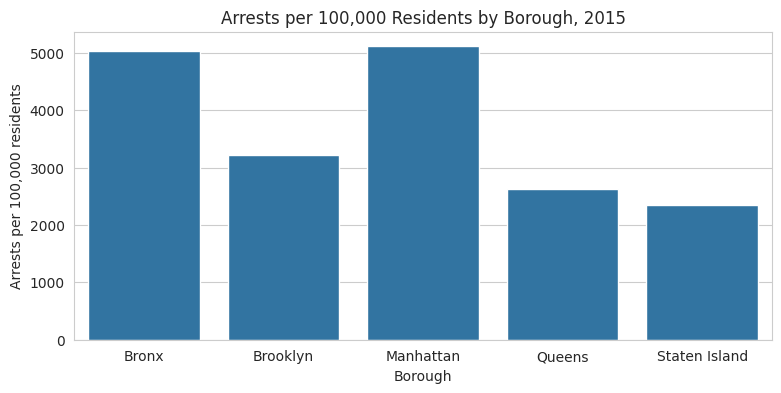

In [17]:
sns.barplot(data=rates_2015, x='borough', y='arrest_rate')
plt.title(label='Arrests per 100,000 Residents by Borough, 2015')
plt.xlabel(xlabel='Borough')
plt.ylabel(ylabel='Arrests per 100,000 residents')

### Answer the Main Question

In 2015, Brooklyn recorded the most arrests (83,892), with Manhattan close behind (83,602). Manhattan had about 1.6 million residents and Brooklyn about 2.6 million, so Manhattan's rate was much higher: 5,109.9 arrests per 100,000 residents, compared with 3,215.7 in Brooklyn. Manhattan had the highest rate, followed closely by the Bronx at 5,028.2. Brooklyn ranked first by count and third by rate.

## Part 6: What Must Match

The ACLU report builds its arrest rates the same way: arrest counts from one source, population figures from another. Our merge lined up the two sources by place and year. Three questions decide what the rate measures.

- **Place.** The NYPD records the borough where an arrest happened. The Census Bureau counts people in the county where they live. Manhattan draws commuters, tourists, and visitors from the other boroughs and beyond, so some of its arrests involve people who live elsewhere.
- **Year.** Each year's arrests are divided by the same year's population estimate.
- **What is counted.** `arrests` counts arrest events. One person arrested twice adds two.

**Question:** Manhattan's rate divides arrests of residents and visitors by its residents alone. How does that affect the comparison between Manhattan and the Bronx?

## Hands-On Exercises

Each exercise has two parts. Part A repeats an example with a different column or table. Part B changes the comparison.

### Exercise 1: Felony Arrest Rates

**Part A:** Add a `felony_rate` column to `rates`: felony arrests per 100,000 residents, rounded to one decimal. Display the 2015 rows sorted by `felony_rate`.

**Part B:** Use `.isin()` to select 2013 and 2015. Draw a bar chart of `felony_rate` by borough with `hue='year'`.

**Question:** Is the borough with the highest felony rate in 2015 the same borough with the highest overall arrest rate? How did each borough's felony rate change from 2013 to 2015?

In [ ]:
# Part A: Add felony_rate to rates, then display the 2015 rows sorted by felony_rate.

In [ ]:
# Part B: Select 2013 and 2015 and draw felony_rate by borough with hue='year'.

### Exercise 2: Merge in the Other Order

**Part A:** Merge `places` onto `population` so every population row gets a `borough` column. Name the result `population_borough` and check its number of rows.

**Part B:** Merge `arrests` with `population_borough` on `borough` and `year`, keeping every arrest row. Calculate `arrest_rate` and compare it with the rates in Part 5.

**Question:** Which table is on the left in each merge, and why does the final result have 15 rows?

In [ ]:
# Part A: Merge places onto population on county and check the number of rows.

In [ ]:
# Part B: Merge arrests with population_borough on borough and year, then calculate arrest_rate.

## Reference: Merging Two Tables

```python
# Add a column from a lookup table
arrests_county = pd.merge(left=arrests, right=places, on='borough', how='left')

# Match on two columns
rates = pd.merge(left=arrests_county, right=population, on=['county', 'year'], how='left')

# Check the result: row count and missing values
len(rates)
rates['population'].isna().sum()

# Rate per 100,000 residents
rates['arrest_rate'] = (rates['arrests'] / rates['population'] * 100000).round(decimals=1)
```

| What you see | Cause | Fix |
|---|---|---|
| `KeyError` naming the `on=` column | One table lacks a column with that name | Merge in a table that adds the column, such as `places` |
| More rows than expected, with `year_x` and `year_y` | The merge matched on too few columns | List every column that identifies a row: `on=['county', 'year']` |
| `NaN` values after a merge | Some rows found no match | Compare the two tables' `.unique()` values for the `on=` columns |
| Fewer rows than expected after `how='inner'` | Some rows found no match and were dropped | Merge with `how='left'`, then filter for the `NaN` rows |
| Rates far too high or too low | Population from a different place or year | Match the place and year of the counts |